Calculate transitions within and between item categories. Build a category lookup for the selected materials, count observed transitions relative to available opportunities and save the figure.

## Settings

`data_paths` and `data_labels` select saved responses to compare. An explicit `data_path`
uses the existing single-input mode. Set the condition queries and analysis controls below.
See the [overview](../templates.qmd#from-a-template-to-a-run) for input files, parameter injection and independent jobs.


In [1]:
#| code-summary: "1 — Set the parameters for this run"


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/catcrp"


# Analysis and uncertainty settings
confidence_level = 0.95
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "category_crp"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None
trial_queries = ["data['list_type'] == 1"]
labels = ["Mixed lists"]
selection_label = "Mixed lists"

category_field = "valence"
category_features_path = None  # Optional lookup indexed by item ID minus one.
feature_column = 6  # Used for a two-dimensional category feature file.


# Figure appearance
color_cycle = None
ylim = None
yticks = None

complete_lists_only = False

contrast_name = None

feature_label = "Relation to preceding recall"


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "d919f1ad6aeacc7a36c40b96e365316219a7f40a"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths)
        + ([category_features_path] if category_features_path else []),
        revision=revision,
    )


In [3]:
#| code-summary: "3 — Import packages"

from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr.analyses.distcrp import plot_cat_crp
from jaxcmr.helpers import generate_trial_mask, load_data, save_figure


## Build the lookup from the selected observations

`category_field` supplies a category at each study position. The plotter needs one category
per global item identifier, so each item must have a consistent assignment within the
selected observations. Selecting another condition can use a different assignment.

The code maps distinct category values to consecutive integer codes. This preserves category
identity regardless of the numerical spacing of the original values. Lookup entry `i - 1`
belongs to item ID `i`; unused vocabulary entries remain missing. The source file is unchanged.

Set `category_features_path` to use an external item-category lookup instead of
`category_field`. It may be a vector or an item-by-feature matrix; `feature_column`
selects the column in a matrix. Row `i - 1` belongs to item ID `i`. Category values
are converted to the same integer codes used by the default route. Supply custom
feature files yourself, including in Colab.

In [4]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

np.random.seed(plot_seed)
output_dir = Path(output_dir)
figure_dir = Path(figure_dir) if figure_dir is not None else output_dir

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [5]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [6]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed lists: 246 lists, 123 participants
CMR / Mixed lists: 2460 lists, 123 participants
Source-only eCMR / Mixed lists: 2460 lists, 123 participants
Broader eCMR / Mixed lists: 2460 lists, 123 participants


In [7]:
#| code-summary: "7 — Load optional item-category features"

category_features = np.load(category_features_path) if category_features_path else None
if category_features is not None and category_features.ndim == 2:
    category_features = category_features[:, feature_column]


In [8]:
#| code-summary: "8 — Collect categories for selected valid study items"

ids_blocks, category_blocks = [], []
for dataset, masks in zip(datasets, masks_by_dataset):
    selected = np.logical_or.reduce([np.asarray(mask) for mask in masks])
    ids = np.asarray(dataset["pres_itemids"])[selected].astype(int)
    categories = (
        category_features[np.maximum(ids - 1, 0)]
        if category_features is not None
        else np.asarray(dataset[category_field])[selected]
    )
    if categories.shape != ids.shape or not np.isfinite(categories[ids > 0]).all():
        raise ValueError("Supply one finite category per valid study item.")
    ids_blocks.append(ids[ids > 0])
    category_blocks.append(categories[ids > 0])


In [9]:
#| code-summary: "9 — Build a consistent item-category lookup"

ids = np.concatenate(ids_blocks)
categories = np.concatenate(category_blocks)
category_values = np.unique(categories)
category_by_item = np.full(int(ids.max()), np.nan)
for item_id in np.unique(ids):
    values = np.unique(categories[ids == item_id])
    if len(values) != 1:
        raise ValueError(
            f"Item {item_id} has conflicting categories across the selected inputs."
        )
    category_by_item[item_id - 1] = np.searchsorted(category_values, values[0])
print(
    tabulate(
        {
            "Category value": category_values,
            "Analysis code": np.arange(len(category_values)),
        },
        headers="keys",
        floatfmt=".4g",
    )
)


  Category value    Analysis code
----------------  ---------------
              -1                0
               0                1


## Calculate and plot

At each transition, a category bin is available if it contains an eligible next item. Observed
choices are divided by those opportunities, separately for same and different categories. These
two values need not sum to one. Selections containing only one category provide no opportunities for a different-category transition.

In [10]:
#| code-summary: "10 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


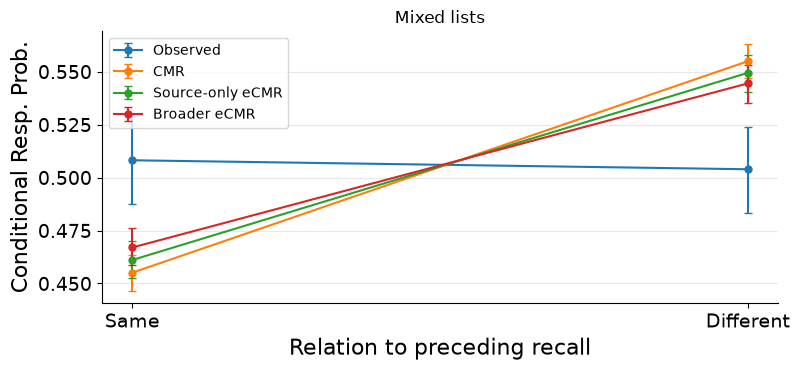

In [11]:
#| code-summary: "11 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for ax, panel in zip(axes.ravel(), panels):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_cat_crp(
        panel_data,
        panel_masks,
        features=jnp.asarray(category_by_item),
        feature_label=feature_label,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        axis=ax,
    )
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str)


## Interpret and adapt

Compare same- and different-category probabilities after accounting for their opportunities. A pure-category selection has no different-category opportunities. Other properties of the materials can covary with category, so this contrast alone does not identify a mechanism.

